# Linear Regression – Dự đoán chi phí bảo hiểm (insurance.csv)

**Các bước:** 1. Đọc dữ liệu → 2. EDA → 3. Tiền xử lý (kèm kiểm tra đa cộng tuyến) → 4. Cài đặt từ đầu (NumPy) → 5. So sánh sklearn → 6. Đánh giá và phân tích sai số → 7. So sánh các phương án → 8. Kết luận

## 1. Đọc dữ liệu
Upload `insurance.csv` (Kaggle: mirichoi0218/insurance) lên Colab.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv("insurance.csv")
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. EDA

### 2.1 Kiểu dữ liệu

In [3]:
df.info()
print()
print("Cột số:        ", df.select_dtypes(include="number").columns.tolist())
print("Cột phân loại: ", df.select_dtypes(exclude="number").columns.tolist())
print()
print(df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Cột số:         ['age', 'bmi', 'children', 'charges']
Cột phân loại:  ['sex', 'smoker', 'region']

age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64


**Nhận xét:** 4 cột số (`age`, `bmi`, `children`, `charges`) và 3 cột phân loại (`sex`, `smoker`, `region`) cần mã hóa trước khi đưa vào mô hình.

### 2.2 Giá trị thiếu và thống kê mô tả

In [4]:
print(df.isna().sum())
df.describe()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### 2.3 Biểu đồ

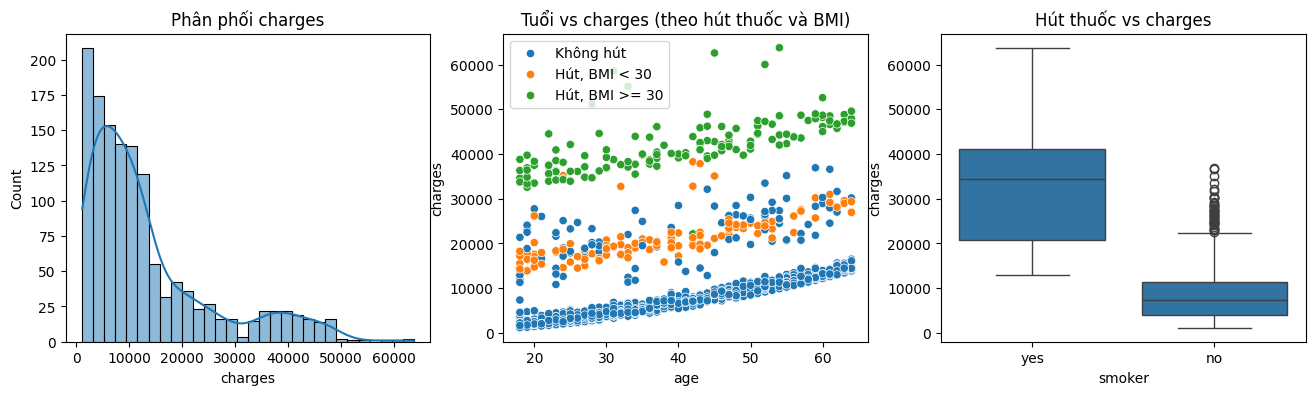

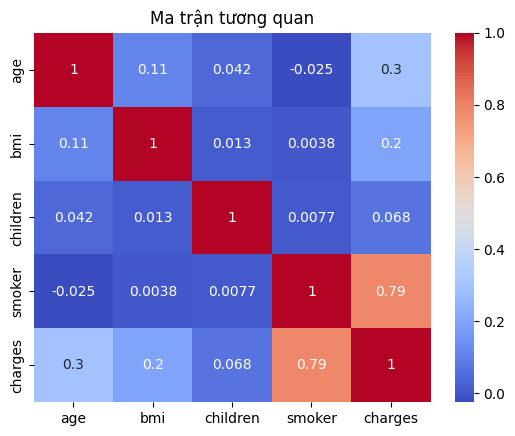

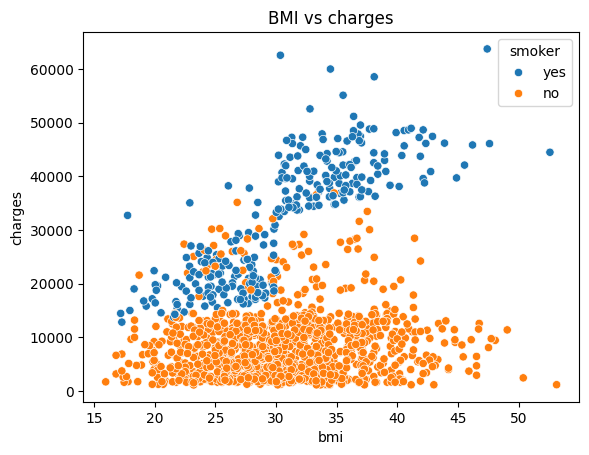

smoker=no: corr(bmi, charges) = 0.084 | corr(age, charges) = 0.628
smoker=yes: corr(bmi, charges) = 0.806 | corr(age, charges) = 0.368


In [5]:
# Nhóm theo hút thuốc và BMI (biến phụ, KHÔNG gán vào df để không lọt vào mô hình)
nhom = np.where(df["smoker"] == "no", "Không hút",
        np.where(df["bmi"] >= 30, "Hút, BMI >= 30", "Hút, BMI < 30"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["charges"], kde=True, ax=ax[0]); ax[0].set_title("Phân phối charges")
sns.scatterplot(data=df, x="age", y="charges", hue=nhom,
                hue_order=["Không hút", "Hút, BMI < 30", "Hút, BMI >= 30"], ax=ax[1])
ax[1].set_title("Tuổi vs charges (theo hút thuốc và BMI)")
sns.boxplot(data=df, x="smoker", y="charges", ax=ax[2]); ax[2].set_title("Hút thuốc vs charges")
plt.show()

df_corr = df.copy()
df_corr["smoker"] = (df_corr["smoker"] == "yes").astype(int)
sns.heatmap(df_corr[["age", "bmi", "children", "smoker", "charges"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Ma trận tương quan")
plt.show()

sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs charges")
plt.show()

# Tương quan riêng từng nhóm: BMI chỉ liên quan mạnh ở người hút thuốc
for g in ["no", "yes"]:
    d = df[df["smoker"] == g]
    print(f"smoker={g}: corr(bmi, charges) = {d['bmi'].corr(d['charges']):.3f} | corr(age, charges) = {d['age'].corr(d['charges']):.3f}")

**Nhận xét:** dữ liệu không thiếu giá trị; `charges` lệch phải; người hút thuốc có chi phí cao hơn hẳn; chi phí tăng đều theo tuổi; BMI chỉ làm tăng chi phí ở nhóm hút thuốc, gần như không ảnh hưởng ở nhóm không hút (tương quan BMI–charges khoảng 0,8 ở người hút so với khoảng 0,08 ở người không hút).

### 2.4 Phí bảo hiểm theo bốn nhóm (hút thuốc × BMI)

In [6]:
nhom4 = np.select([(df["smoker"] == "no") & (df["bmi"] < 30),
                   (df["smoker"] == "no") & (df["bmi"] >= 30),
                   (df["smoker"] == "yes") & (df["bmi"] < 30)],
                  ["Không hút, BMI<30", "Không hút, BMI>=30", "Hút, BMI<30"],
                  default="Hút, BMI>=30")
tb = df.groupby(nhom4)["charges"].agg(["count", "median", "mean"]).round(0)
display(tb)

med = tb["median"]
print("Hút thuốc làm phí (trung vị) gấp:",
      round(med["Hút, BMI<30"] / med["Không hút, BMI<30"], 1), "lần khi BMI<30 và",
      round(med["Hút, BMI>=30"] / med["Không hút, BMI>=30"], 1), "lần khi BMI>=30")
print("BMI>=30 làm phí tăng thêm (trung vị): người không hút =",
      int(med["Không hút, BMI>=30"] - med["Không hút, BMI<30"]),
      "| người hút thuốc =", int(med["Hút, BMI>=30"] - med["Hút, BMI<30"]))

,count,median,mean
"Hút, BMI<30",129,20167.0,21363.0
"Hút, BMI>=30",145,40904.0,41558.0
"Không hút, BMI<30",502,6762.0,7977.0
"Không hút, BMI>=30",562,8076.0,8843.0


Hút thuốc làm phí (trung vị) gấp: 3.0 lần khi BMI<30 và 5.1 lần khi BMI>=30
BMI>=30 làm phí tăng thêm (trung vị): người không hút = 1314 | người hút thuốc = 20737


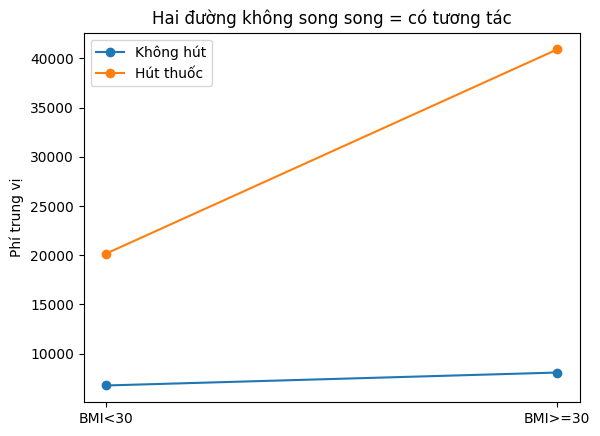

In [17]:
x = ["BMI<30", "BMI>=30"]
plt.plot(x, [med["Không hút, BMI<30"], med["Không hút, BMI>=30"]], marker="o", label="Không hút")
plt.plot(x, [med["Hút, BMI<30"], med["Hút, BMI>=30"]], marker="o", label="Hút thuốc")
plt.ylabel("Phí trung vị"); plt.legend(); plt.title("Hai đường không song song = có tương tác")
plt.show()

**Insight:** béo phì (BMI >= 30) chỉ làm phí tăng khoảng 1.300 đô ở người không hút thuốc, nhưng tăng khoảng 20.700 đô ở người hút thuốc. Hút thuốc làm phí gấp khoảng 3 lần khi BMI < 30 và khoảng 5 lần khi BMI >= 30. Tức là hai yếu tố này **khuếch đại lẫn nhau**, đó là lý do cần đặc trưng tương tác `smoker × bmi`.

## 3. Tiền xử lý
One-hot encode biến phân loại, chia train/test 80/20, tạo đặc trưng tương tác `smoker × (bmi − BMI trung bình)`, rồi chuẩn hóa (fit trên train).
Trừ BMI trung bình **trước khi nhân** để `smoker_bmi` không còn gần như trùng với `smoker_yes` (xem mục 3.1).

In [7]:
X = pd.get_dummies(df.drop(columns="charges"), drop_first=True).astype(float)
y = df["charges"].values

X_train_df, X_test_df, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_df, X_test_df = X_train_df.copy(), X_test_df.copy()

bmi_tb = X_train_df["bmi"].mean()                 # trung bình tính trên train
for d in (X_train_df, X_test_df):
    d["smoker_bmi"] = d["smoker_yes"] * (d["bmi"] - bmi_tb)   # tương tác: BMI chỉ tác động mạnh ở người hút thuốc

names = X_train_df.columns.tolist()
X_train, X_test = X_train_df.values, X_test_df.values

sc = StandardScaler().fit(X_train)                # chỉ fit trên train để tránh rò rỉ dữ liệu
Xtr, Xte = sc.transform(X_train), sc.transform(X_test)
print(names)
print("BMI trung bình (train):", round(bmi_tb, 2))

['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'smoker_bmi']
BMI trung bình (train): 30.56


### 3.1 Kiểm tra đa cộng tuyến
**Vấn đề:** `smoker_bmi` được tạo từ `smoker_yes` và `bmi`; nếu nhân trực tiếp thì nó gần như lặp lại `smoker_yes` (bằng 0 với người không hút và khoảng 30 với người hút).
**Công thức:** VIF = 1 / (1 − R²) với R² là mức một feature được các feature còn lại giải thích; VIF > 10 là cao. Số điều kiện = λmax / λmin của (1/n)·XᵀX; càng lớn thì Gradient Descent càng chậm.

In [8]:
def vif_table(D):
    out = {}
    for c in D.columns:
        others = D.drop(columns=c)
        r2 = LinearRegression().fit(others, D[c]).score(others, D[c])
        out[c] = 1 / (1 - r2)
    return pd.Series(out)

def so_dieu_kien(D):
    Z = StandardScaler().fit_transform(D.values)
    Zb = np.hstack([np.ones((len(Z), 1)), Z])
    lam = np.linalg.eigvalsh(Zb.T @ Zb / len(Z))
    return lam.max() / lam.min()

raw = X_train_df.copy()
raw["smoker_bmi"] = raw["smoker_yes"] * raw["bmi"]        # nhân trực tiếp, chưa trừ BMI trung bình

vif = pd.DataFrame({"Nhân trực tiếp": vif_table(raw),
                    "Đã trừ BMI trung bình": vif_table(X_train_df)}).round(1)
display(vif)
print("Số điều kiện λmax/λmin: nhân trực tiếp =", round(so_dieu_kien(raw), 1),
      "| đã trừ BMI trung bình =", round(so_dieu_kien(X_train_df), 1))

,Nhân trực tiếp,Đã trừ BMI trung bình
age,1.0,1.0
bmi,1.4,1.4
children,1.0,1.0
sex_male,1.0,1.0
smoker_yes,25.7,1.0
region_northwest,1.5,1.5
region_southeast,1.6,1.6
region_southwest,1.5,1.5
smoker_bmi,26.0,1.3


Số điều kiện λmax/λmin: nhân trực tiếp = 104.0 | đã trừ BMI trung bình = 5.3


**Nhận xét:** nhân trực tiếp làm VIF của `smoker_yes` và `smoker_bmi` lên cỡ 25; trừ BMI trung bình đưa chúng về gần 1 và giảm số điều kiện từ cỡ 100 xuống cỡ 5, mà **không đổi dự đoán** (cùng một mô hình, chỉ đổi cách biểu diễn).

## 4. Cài đặt từ đầu bằng NumPy
**Vấn đề:** tìm w sao cho ŷ = Xw sai lệch ít nhất so với y.
**Trực giác:** chọn đường thẳng làm tổng bình phương khoảng cách tới các điểm nhỏ nhất.
**Công thức:** Normal Equation w = (XᵀX)⁻¹Xᵀy; Gradient Descent w ← w − α·(1/n)·Xᵀ(Xw − y).
**Bản chất:** cực tiểu hóa bình phương sai số của một hàm lồi nên có nghiệm tối ưu duy nhất.

Chênh lệch lớn nhất giữa 2 nghiệm: 3.081029439044869e-05


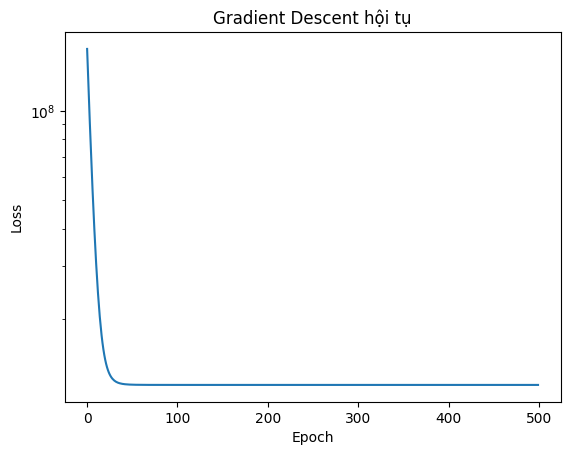

In [9]:
def add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])

def normal_equation(X, y):
    Xb = add_bias(X)
    return np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y

def gradient_descent(X, y, lr=0.1, epochs=500):
    Xb = add_bias(X)
    w = np.zeros(Xb.shape[1])
    losses = []
    for _ in range(epochs):
        err = Xb @ w - y
        losses.append((err ** 2).mean() / 2)
        w -= lr * (Xb.T @ err) / len(y)
    return w, losses

def predict(X, w):
    return add_bias(X) @ w

w_ne = normal_equation(Xtr, y_train)
w_gd, losses = gradient_descent(Xtr, y_train)
print("Chênh lệch lớn nhất giữa 2 nghiệm:", np.abs(w_ne - w_gd).max())

plt.plot(losses); plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Gradient Descent hội tụ")
plt.show()

Sau khi trừ BMI trung bình, `lr = 0.1` và 500 epoch là đủ để Gradient Descent khớp Normal Equation (trước đó với `smoker × bmi` nhân trực tiếp phải dùng `lr = 0.5` và 2000 epoch).

## 5. So sánh với scikit-learn

In [10]:
sk = LinearRegression().fit(Xtr, y_train)
print("Hệ số khớp sklearn:", np.allclose(w_ne[1:], sk.coef_), "| Intercept khớp:", np.allclose(w_ne[0], sk.intercept_))

Hệ số khớp sklearn: True | Intercept khớp: True


## 6. Đánh giá

In [11]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

res = pd.DataFrame({
    "NumPy (NE) - Train": metrics(y_train, predict(Xtr, w_ne)),
    "NumPy (NE) - Test":  metrics(y_test,  predict(Xte, w_ne)),
    "NumPy (GD) - Test":  metrics(y_test,  predict(Xte, w_gd)),
    "sklearn - Test":     metrics(y_test,  sk.predict(Xte)),
}).T
res.round(3)

,MSE,RMSE,MAE,R2
NumPy (NE) - Train,2.394920e+07,4893.792,2974.766,0.834
NumPy (NE) - Test,2.091972e+07,4573.808,2756.899,0.865
NumPy (GD) - Test,2.091972e+07,4573.808,2756.899,0.865
sklearn - Test,2.091972e+07,4573.808,2756.899,0.865


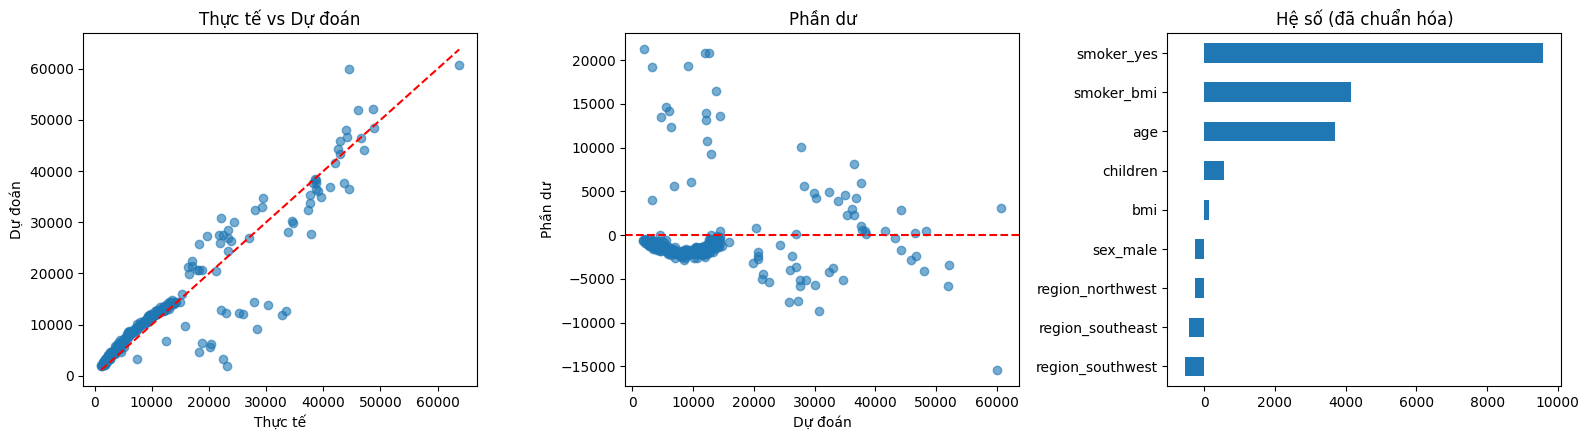

In [12]:
y_pred = predict(Xte, w_ne)
resid = y_test - y_pred

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(y_test, y_pred, alpha=0.6)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Thực tế"); ax[0].set_ylabel("Dự đoán"); ax[0].set_title("Thực tế vs Dự đoán")
ax[1].scatter(y_pred, resid, alpha=0.6); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Dự đoán"); ax[1].set_ylabel("Phần dư"); ax[1].set_title("Phần dư")
pd.Series(sk.coef_, index=names).sort_values().plot(kind="barh", ax=ax[2]); ax[2].set_title("Hệ số (đã chuẩn hóa)")
plt.tight_layout(); plt.show()

### Hệ số w của mô hình
Bảng 1: trên dữ liệu đã chuẩn hóa (so độ mạnh giữa các feature, so ba nghiệm NE, GD, sklearn). Bảng 2: quy về đơn vị gốc (đô la trên mỗi đơn vị feature). Vì BMI đã trừ trung bình trong `smoker_bmi`, hệ số `smoker_yes` là **tác động của hút thuốc tại BMI trung bình**.

In [13]:
ten = ["bias"] + names

W = pd.DataFrame({"NE": w_ne, "GD": w_gd,
                  "sklearn": np.r_[sk.intercept_, sk.coef_]}, index=ten)
display(W.round(2))

w_goc = w_ne[1:] / sc.scale_
b_goc = w_ne[0] - np.sum(w_ne[1:] * sc.mean_ / sc.scale_)
display(pd.Series(np.r_[b_goc, w_goc], index=ten, name="w (đơn vị gốc)").round(2))

i_bmi, i_sb, i_sy = names.index("bmi"), names.index("smoker_bmi"), names.index("smoker_yes")
print("Tác động của hút thuốc tại BMI trung bình:", round(w_goc[i_sy]), "đô")
print("Độ dốc BMI, người không hút:", round(w_goc[i_bmi], 1), "đô mỗi điểm BMI")
print("Độ dốc BMI, người hút thuốc:", round(w_goc[i_bmi] + w_goc[i_sb], 1), "đô mỗi điểm BMI")

,NE,GD,sklearn
bias,13346.09,13346.09,13346.09
age,3705.22,3705.22,3705.22
bmi,122.33,122.33,122.33
children,563.53,563.53,563.53
sex_male,-262.54,-262.54,-262.54
smoker_yes,9595.71,9595.71,9595.71
region_northwest,-269.38,-269.38,-269.38
region_southeast,-426.72,-426.72,-426.72
region_southwest,-531.74,-531.74,-531.74
smoker_bmi,4141.58,4141.58,4141.58


,w (đơn vị gốc)
bias,-2041.66
age,263.39
bmi,20.25
children,463.65
sex_male,-525.23
smoker_yes,23743.23
region_northwest,-631.42
region_southeast,-967.48
region_southwest,-1233.43
smoker_bmi,1470.86


Tác động của hút thuốc tại BMI trung bình: 23743 đô
Độ dốc BMI, người không hút: 20.3 đô mỗi điểm BMI
Độ dốc BMI, người hút thuốc: 1491.1 đô mỗi điểm BMI


In [18]:
base = r2_score(y_test, sk.predict(Xte))
rows = []
for c in names:
    cols = [n for n in names if n != c]
    s = StandardScaler().fit(X_train_df[cols])
    m = LinearRegression().fit(s.transform(X_train_df[cols]), y_train)
    r2 = r2_score(y_test, m.predict(s.transform(X_test_df[cols])))
    rows.append({"feature": c, "R2 khi bỏ": r2, "mất R2": base - r2})
pd.DataFrame(rows).sort_values("mất R2", ascending=False).round(3)

,feature,R2 khi bỏ,mất R2
4,smoker_yes,0.300,0.565
0,age,0.776,0.089
8,smoker_bmi,0.784,0.082
2,children,0.861,0.004
6,region_southeast,0.863,0.003
7,region_southwest,0.864,0.001
3,sex_male,0.865,0.000
1,bmi,0.865,0.000
5,region_northwest,0.865,0.000


### Phân tích sai số
Mô hình sai nhiều nhất ở nhóm nào? Chia tập test theo nhóm hút thuốc × BMI, rồi lọc các ca bị dự đoán **thấp hơn thực tế** quá 8.000 đô.

In [14]:
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)
test_df = df.iloc[idx_test].copy()
assert np.allclose(test_df["charges"].values, y_test)   # kiểm tra đúng hàng của tập test

test_df["du_doan"] = y_pred
test_df["phan_du"] = resid
test_df["sq"] = test_df["phan_du"] ** 2
test_df["abs"] = test_df["phan_du"].abs()
test_df["nhom"] = np.where(test_df["smoker"] == "no", "Không hút",
                    np.where(test_df["bmi"] >= 30, "Hút, BMI>=30", "Hút, BMI<30"))

by = test_df.groupby("nhom").agg(n=("sq", "size"), MAE=("abs", "mean"),
                                 MSE=("sq", "mean"), SSE=("sq", "sum"))
by["RMSE"] = np.sqrt(by.pop("MSE"))
by["% tổng sai số bình phương"] = 100 * by.pop("SSE") / test_df["sq"].sum()
display(by[["n", "MAE", "RMSE", "% tổng sai số bình phương"]].round(1))

lon = test_df[test_df["phan_du"] > 8000]
print(f"Số ca bị đoán thấp hơn thực tế > 8000: {len(lon)} / {len(test_df)}")
print("Phân bố hút thuốc trong nhóm này:", lon["smoker"].value_counts().to_dict())
print(f"Tỉ lệ đóng góp vào tổng sai số bình phương: {lon['sq'].sum() / test_df['sq'].sum():.0%}")
lon[["age", "bmi", "smoker", "charges", "du_doan"]].round(0).head(10)

,n,MAE,RMSE,% tổng sai số bình phương
nhom,,,,
"Hút, BMI<30",24,4922.4,6335.7,17.2
"Hút, BMI>=30",30,3595.5,4767.4,12.2
Không hút,214,2396.5,4302.4,70.7


Số ca bị đoán thấp hơn thực tế > 8000: 17 / 268
Phân bố hút thuốc trong nhóm này: {'no': 14, 'yes': 3}
Tỉ lệ đóng góp vào tổng sai số bình phương: 71%


,age,bmi,smoker,charges,du_doan
429,27,30.0,no,18805.0,6445.0
806,40,41.0,no,28477.0,9165.0
925,50,32.0,no,25333.0,12180.0
770,61,36.0,no,27941.0,14389.0
1098,52,31.0,no,23046.0,12280.0
289,52,26.0,no,25993.0,12088.0
430,19,33.0,no,23083.0,1874.0
115,60,29.0,no,30260.0,13816.0
599,52,38.0,no,33472.0,12710.0
128,32,18.0,yes,32734.0,11965.0


**Insight:** người không hút thuốc có MAE thấp nhất nhưng lại chiếm phần lớn tổng sai số bình phương, vì một số ít ca có phí cao bất thường bị đoán thấp. Ở hai nhóm hút thuốc, mẫu test nhỏ (khoảng 24 và 30 người) nên con số RMSE kém ổn định, không nên kết luận quá chắc.

### Kiểm tra độ bền: chia hẳn hai mô hình theo hút thuốc
Nếu một số hạng tương tác đã đủ thì việc chia hẳn thành hai mô hình (mỗi nhóm hút thuốc có toàn bộ hệ số riêng) không nên tốt hơn đáng kể.

In [15]:
cot = [c for c in names if c not in ("smoker_yes", "smoker_bmi")]
pred_sep = np.zeros(len(y_test))
for g in [0.0, 1.0]:
    mtr = X_train_df["smoker_yes"].values == g
    mte = X_test_df["smoker_yes"].values == g
    pred_sep[mte] = LinearRegression().fit(X_train_df.loc[mtr, cot], y_train[mtr]).predict(X_test_df.loc[mte, cot])

print("Chia hai mô hình theo hút thuốc:   R2 =", round(r2_score(y_test, pred_sep), 4),
      "| RMSE =", round(np.sqrt(mean_squared_error(y_test, pred_sep)), 1))
print("Một mô hình có smoker_bmi:         R2 =", round(r2_score(y_test, y_pred), 4),
      "| RMSE =", round(np.sqrt(mean_squared_error(y_test, y_pred)), 1))

Chia hai mô hình theo hút thuốc:   R2 = 0.8644 | RMSE = 4588.1
Một mô hình có smoker_bmi:         R2 = 0.8653 | RMSE = 4573.8


**Nhận xét:** hai cách cho kết quả gần như bằng nhau, nên một số hạng tương tác `smoker × bmi` đã nắm gần hết phần tương tác giữa hút thuốc và các feature khác.

## 7. So sánh các phương án (kèm cross-validation 5 fold)
Chuẩn hóa nằm trong pipeline nên cross-validation không bị rò rỉ dữ liệu.

In [20]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

X0 = pd.get_dummies(df.drop(columns="charges"), drop_first=True).astype(float)
X1 = X0.copy(); X1["smoker_bmi"] = X1["smoker_yes"] * (X1["bmi"] - X1["bmi"].mean())
X2 = X1.copy()
cases = [
    ("Linear - không tương tác (model gốc)", X0, LinearRegression()),
    ("Linear + smoker_bmi (mô hình chính)",  X1, LinearRegression()),
]
kf = KFold(5, shuffle=True, random_state=42)
rows = []
for name, Xf, model in cases:
    pipe = make_pipeline(StandardScaler(), model)
    Xa, Xb, ya, yb = train_test_split(Xf.values, y, test_size=0.2, random_state=42)
    pipe.fit(Xa, ya); p = pipe.predict(Xb)
    cv = cross_val_score(pipe, Xf.values, y, cv=kf, scoring="r2")
    rows.append({"Phương án": name, "R2 test": r2_score(yb, p),
                 "RMSE test": np.sqrt(mean_squared_error(yb, p)),
                 "CV R2": cv.mean(), "CV std": cv.std()})
pd.DataFrame(rows).round(3)

,Phương án,R2 test,RMSE test,CV R2,CV std
0,Linear - không tương tác (model gốc),0.784,5796.285,0.740,0.058
1,Linear + smoker_bmi (mô hình chính),0.865,4573.808,0.834,0.037


**Nhận xét:** thêm `smoker × bmi` làm CV R² tăng từ 0,740 lên 0,834 và RMSE test giảm từ 5.796 xuống 4.574. Mức tăng lớn hơn độ dao động giữa các fold nên cải thiện đáng tin.

## 8. Kết luận
- Nghiệm NumPy (Normal Equation) khớp sklearn; Gradient Descent hội tụ về cùng nghiệm (lr = 0,1; 500 epoch) sau khi xử lý đa cộng tuyến.
- `smoker` là yếu tố mạnh nhất. BMI chỉ làm tăng chi phí rõ ở người hút thuốc (độ dốc khoảng 1.490 đô mỗi điểm BMI, so với khoảng 20 ở người không hút), nên em thêm đặc trưng tương tác `smoker × bmi`.
- Nhân trực tiếp `smoker × bmi` làm VIF của hai cột liên quan lên cỡ 25; trừ BMI trung bình trước khi nhân đưa VIF về gần 1 mà không đổi dự đoán.
- Phí (trung vị) của người hút thuốc gấp khoảng 3 lần khi BMI < 30 và khoảng 5 lần khi BMI >= 30; béo phì chỉ làm phí tăng khoảng 1.300 đô ở người không hút.
- Trên tập test: R² = 0,865, RMSE ≈ 4.574, MAE ≈ 2.757. R² train = 0,834, hai số gần nhau nên không có dấu hiệu overfit. Chia hẳn hai mô hình theo hút thuốc không tốt hơn, và cross-validation cho thấy cải thiện từ tương tác là ổn định.
- Hạn chế: một nhóm nhỏ người (chủ yếu không hút thuốc) có chi phí cao bất thường bị dự đoán thấp, và nhóm này chiếm phần lớn sai số. Các cột hiện có không giải thích được nhóm này.